# Is the Night shift gap behind the "morning team" breaches?

**Hypothesis (Kabir):** the June 2025 reshuffle left the Night shift (22:00-06:00 IST) empty, so tickets created at night wait until morning, breach their first-response target, and are resolved by - and therefore blamed on - the morning team.

**What would support it** (all five should hold):
1. Nobody is rostered on Night after 29 Jun 2025.
2. The breach rate of tickets *created* in the Night shift jumps after that date; Morning- and Day-created tickets do not move.
3. The jump is confined to Night hours (22:00-06:00 IST), not spread across the day.
4. Most breaches counted against Morning agents were created at night.
5. Judged only on tickets created in their own shift, Morning agents look like everyone else.

**What would reject it:** the Night breach rate stays flat, or Morning-created tickets breach just as much, or Morning agents breach on their own tickets.

Breach = first human reply later than the policy section 3 target (chat 15 min, voice callback 2 h, social 4 h, email 8 h), measured from ticket creation. All shifts are IST (policy section 7).

## 1. Setup and cleaning

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from pathlib import Path
from math import sqrt
from IPython.display import display

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25})

DATA = Path('..') / 'data'
SHIFTS = ['Morning', 'Day', 'Night']
COL = {'Morning': '#d98324', 'Day': '#3b7dd8', 'Night': '#5b2a86'}
TARGET_MIN = {'chat': 15, 'voice': 120, 'social': 240, 'email': 480}   # policy section 3
CUTOVER = pd.Timestamp('2025-06-30')                                  # first day with no Night roster rows

def wilson(k, n, z=1.96):
    k = np.asarray(k, float); n = np.asarray(n, float)
    with np.errstate(divide='ignore', invalid='ignore'):
        p = k / n
        den = 1 + z**2 / n
        centre = (p + z**2 / (2 * n)) / den
        half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

raw = pd.read_csv(DATA / 'ticket.csv', dtype={'csat_score': float})
roster = pd.read_csv(DATA / 'agents.csv', parse_dates=['from_date', 'to_date']).rename(columns={'shift': 'agent_shift'})
roster['to_date'] = roster['to_date'].fillna(pd.Timestamp('2099-12-31'))
print(f'raw tickets: {len(raw):,} rows, {raw.ticket_id.nunique():,} unique ticket_ids')

raw tickets: 11,816 rows, 11,200 unique ticket_ids


### 1a. Duplicate ticket_ids - keep the helpdesk copy

In [2]:
dups = raw[raw.ticket_id.duplicated(keep=False)]
pairs = dups.groupby('ticket_id').source_system.apply(lambda s: tuple(sorted(s)))
print('ticket_ids appearing twice:', pairs.size)
print(pairs.value_counts().to_string())
assert (pairs == ('helpdesk', 'legacy_fd')).all()        # every duplicate is exactly one helpdesk + one legacy row

# Which columns actually differ between the two copies?
cols = [c for c in raw.columns if c not in ('ticket_id', 'source_system')]
g = dups.groupby('ticket_id')
differing = {c: int((g[c].nunique(dropna=False) > 1).sum()) for c in cols}
print('pairs where the copies disagree, by column:', {k: v for k, v in differing.items() if v})

# Keep helpdesk copy: sort so helpdesk comes first, then drop later copies.
tk = (raw.assign(_legacy=raw.source_system.ne('helpdesk'))
         .sort_values(['ticket_id', '_legacy']).drop_duplicates('ticket_id', keep='first')
         .drop(columns='_legacy').reset_index(drop=True))
assert tk.ticket_id.is_unique
print(f'after de-dup: {len(tk):,} tickets  (dropped {len(raw) - len(tk):,} legacy copies)')
print(tk.source_system.value_counts().to_string())

ticket_ids appearing twice: 616
source_system
(helpdesk, legacy_fd)    616
pairs where the copies disagree, by column: {'csat_score': 336}
after de-dup: 11,200 tickets  (dropped 616 legacy copies)
source_system
helpdesk     8079
legacy_fd    3121


Only `csat_score` differs between the two copies (legacy 0 versus helpdesk blank), so keeping the helpdesk copy loses nothing that matters for breach timing.

### 1b. UTC to IST - proved with the voice-callback window
Policy section 2: the IVR only takes callback requests **08:00-22:00 IST**. Voice tickets are therefore a natural clock: the only UTC-to-local offset that puts every voice ticket inside that window is the right one.

1,566 voice tickets (raw, incl. duplicate rows)
offsets with 100% of voice tickets inside 08:00-22:00 local: [5.5]
raw UTC clock range of voice creates : 02:30 - 16:28
after +05:30 the range becomes        : 08:00 - 21:58
share inside the window if left in UTC : 62.7%


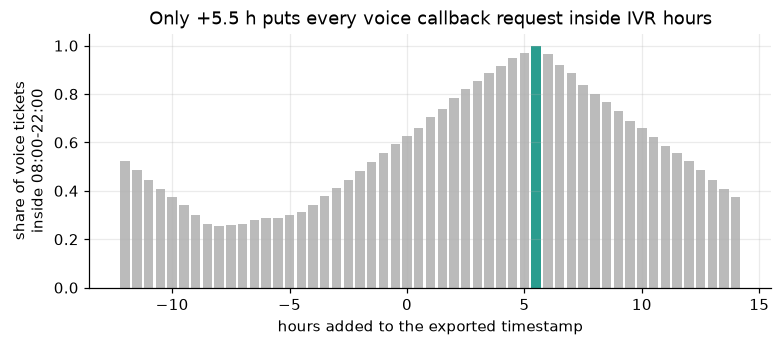

In [3]:
voice = raw[raw.channel == 'voice'].copy()
_ts = pd.to_datetime(voice.created_at)
voice['minute_utc'] = _ts.dt.hour * 60 + _ts.dt.minute

def share_in_window(minutes, offset_min, lo=8*60, hi=22*60):
    local = (minutes + offset_min) % (24 * 60)
    return ((local >= lo) & (local <= hi)).mean()

offsets = list(range(-12 * 60, 14 * 60 + 1, 30))
scan = pd.DataFrame({'offset_h': [o / 60 for o in offsets],
                     'share_in_08_22': [share_in_window(voice.minute_utc, o) for o in offsets]})
for s, d in voice.groupby('source_system'):
    scan[s] = [share_in_window(d.minute_utc, o) for o in offsets]
best = scan.loc[scan.share_in_08_22 == scan.share_in_08_22.max()]
hm = lambda m: f'{m // 60:02d}:{m % 60:02d}'
print(f'{len(voice):,} voice tickets (raw, incl. duplicate rows)')
print('offsets with 100% of voice tickets inside 08:00-22:00 local:', best.offset_h.tolist())
print('raw UTC clock range of voice creates :', hm(voice.minute_utc.min()), '-', hm(voice.minute_utc.max()))
print('after +05:30 the range becomes        :', hm(voice.minute_utc.min() + 330), '-', hm(voice.minute_utc.max() + 330))
print('share inside the window if left in UTC :', f'{share_in_window(voice.minute_utc, 0):.1%}')
assert best.offset_h.tolist() == [5.5]
assert scan.loc[scan.offset_h == 5.5, ['helpdesk', 'legacy_fd']].eq(1).all().all()    # legacy rows use the same clock

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(scan.offset_h, scan.share_in_08_22, width=.4, color=np.where(scan.offset_h == 5.5, '#2a9d8f', '#bbb'))
ax.set(xlabel='hours added to the exported timestamp', ylabel='share of voice tickets\ninside 08:00-22:00',
       title='Only +5.5 h puts every voice callback request inside IVR hours')
plt.show()

`+05:30` is the only offset where all voice tickets (helpdesk and legacy rows alike) fall inside 08:00-22:00 IST. Left in UTC, a large share would look as if it was raised outside IVR hours, and the Night shift would be mis-sized. All timestamps below are IST.

### 1c. Convert, flag breaches, treat legacy CSAT 0 as blank

In [4]:
IST = pd.Timedelta(hours=5, minutes=30)
for c in ['created_at', 'first_response_at', 'resolved_at']:
    tk[c + '_ist'] = pd.to_datetime(tk[c]) + IST
tk = tk.drop(columns=['created_at', 'first_response_at', 'resolved_at'])

n_zero = int((tk.csat_score == 0).sum())
tk['csat_score'] = tk.csat_score.replace(0, np.nan)                 # 0 only ever means "no response" (README)
assert not (tk.csat_score == 0).any()
print(f'csat 0 -> blank on {n_zero:,} rows; remaining scores: {tk.csat_score.value_counts().sort_index().to_dict()}')

def shift_of_hour(h):
    h = np.asarray(h)
    return np.select([(h >= 6) & (h < 14), (h >= 14) & (h < 22)], ['Morning', 'Day'], 'Night')

tk['resp_min'] = (tk.first_response_at_ist - tk.created_at_ist).dt.total_seconds() / 60
assert (tk.resp_min >= 0).all()
tk['breach'] = tk.resp_min > tk.channel.map(TARGET_MIN)            # strictly later than target (policy section 10)
tk['hour'] = tk.created_at_ist.dt.hour
tk['created_shift'] = shift_of_hour(tk.hour)
# "shift day": a Night shift that starts 22:00 on the 29th and runs to 06:00 on the 30th belongs to the 29th
tk['shift_date'] = (tk.created_at_ist - pd.Timedelta(hours=6)).dt.normalize()
tk['month'] = tk.created_at_ist.dt.to_period('M')
tk['period'] = np.where(tk.shift_date < CUTOVER, 'Before 30 Jun 2025', 'From 30 Jun 2025')
PERIODS = ['Before 30 Jun 2025', 'From 30 Jun 2025']

print(f'{len(tk):,} tickets, {tk.breach.sum():,} breaches ({tk.breach.mean():.1%})')
print(pd.crosstab(tk.channel, tk.created_shift)[SHIFTS].to_string())

csat 0 -> blank on 1,730 rows; remaining scores: {1.0: 164, 2.0: 783, 3.0: 1792, 4.0: 1565, 5.0: 689}


11,200 tickets, 2,440 breaches (21.8%)
created_shift  Morning   Day  Night
channel                            
chat              1711  1967   1281
email             1307  1359    981
social             424   458    224
voice              604   884      0


Voice tickets never land in Night (IVR closes at 22:00 IST), as expected. Open and pending tickets still have a first-response time, so they count in the creation-shift views. The resolving-agent views in sections 6 and 7 use only `resolved` and `closed` tickets, because for open and pending tickets `agent_id` is not a resolver.

## 2. Who is rostered on Night over time?

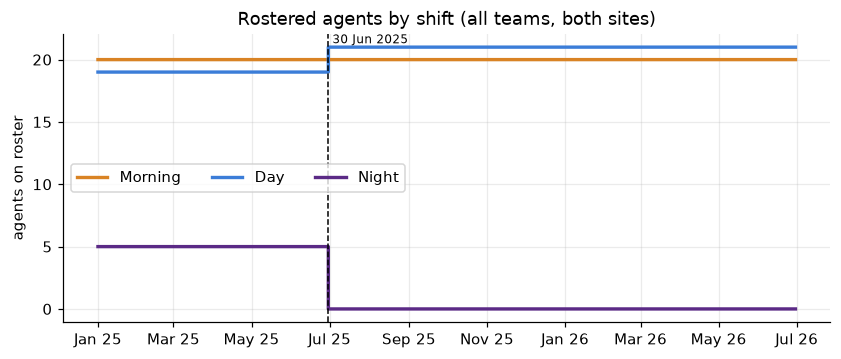

Headcount on selected dates:
            Morning  Day  Night
2025-01-01       20   19      5
2025-06-29       20   19      5
2025-06-30       20   21      0
2025-12-31       20   21      0
2026-06-30       20   21      0

Every roster row for anyone who was ever on Night:
agent_id               name   site            team agent_shift  from_date    to_date
   A3001         Zoya Mehta Indore  Chat Frontline       Night 2021-04-20 2025-06-29
   A3002       Tarun Mishra Indore  Chat Frontline       Night 2023-02-12 2025-06-29
   A3002       Tarun Mishra Indore  Chat Frontline         Day 2025-06-30        NaT
   A3003 Harpreet Deshpande Indore  Chat Frontline       Night 2023-06-14 2025-06-29
   A3003 Harpreet Deshpande Indore  Chat Frontline         Day 2025-06-30        NaT
   A3016      Deepak Jadhav Indore Email Frontline       Night 2023-03-07 2025-06-29
   A3017       Shreya Bhatt Indore Email Frontline       Night 2023-05-22 2025-06-29


In [5]:
days = pd.date_range('2025-01-01', '2026-06-30')
hc = pd.DataFrame({s: [int(((roster.agent_shift == s) & (roster.from_date <= d) & (roster.to_date >= d)).sum()) for d in days]
                   for s in SHIFTS}, index=days)

fig, ax = plt.subplots(figsize=(9, 3.4))
for s in SHIFTS:
    ax.step(hc.index, hc[s], where='post', label=s, color=COL[s], lw=2.2)
ax.axvline(CUTOVER, color='k', ls='--', lw=1); ax.text(CUTOVER, ax.get_ylim()[1], ' 30 Jun 2025', va='top', fontsize=8)
ax.set(ylabel='agents on roster', title='Rostered agents by shift (all teams, both sites)')
ax.legend(ncol=3, loc='center left'); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
plt.show()

print('Headcount on selected dates:')
print(hc.loc[[pd.Timestamp(x) for x in ['2025-01-01', '2025-06-29', '2025-06-30', '2025-12-31', '2026-06-30']]].to_string())
assert hc.loc[:'2025-06-29', 'Night'].min() > 0 and hc.loc['2025-06-30':, 'Night'].max() == 0

ever_night = roster[roster.agent_id.isin(roster[roster.agent_shift == 'Night'].agent_id)].sort_values(['agent_id', 'from_date'])
print('\nEvery roster row for anyone who was ever on Night:')
print(ever_night[['agent_id', 'name', 'site', 'team', 'agent_shift', 'from_date', 'to_date']]
      .assign(to_date=lambda d: d.to_date.replace(pd.Timestamp('2099-12-31'), pd.NaT)).to_string(index=False))

Night is staffed until 29 Jun 2025 and **has no roster rows from 30 Jun 2025 onward**. Two Night chat agents (A3002, A3003) were moved to Day; the other Night agents have no roster row after 29 Jun (the roster does not say whether they left or were reassigned). Premise 1 of the hypothesis holds.

## 3. Monthly breach rate by the shift the ticket was CREATED in

breach rate             tickets created           
created_shift     Morning   Day Night         Morning  Day Night
month                                                           
2025-01             0.143 0.036 0.075              91  112    53
2025-02             0.121 0.121 0.077             132  165    65
2025-03             0.103 0.047 0.156             146  170    90
2025-04             0.068 0.104 0.108             162  163    93
2025-05             0.066 0.125 0.098             167  160    92
2025-06             0.075 0.080 0.104             147  162    96
2025-07             0.099 0.063 0.814             171  207    97
2025-08             0.108 0.104 0.841             278  249   157
2025-09             0.122 0.100 0.805             238  290   154
2025-10             0.101 0.104 0.757             337  345   181
2025-11             0.080 0.090 0.794             325  354   194
2025-12             0.096 0.080 0.754             291  362   183
2026-01             0.112 0.093 0.780             277  353   191
2026-02             0.086 0.076 0.726             243  288   157
2026-03             0.107 0.081 0.821             271  332   179
2026-04             0.091 0.104 0.842             252  308   165
2026-05             0.106 0.079 0.791             245  330   172
2026-06             0.084 0.088 0.778             273  318   167

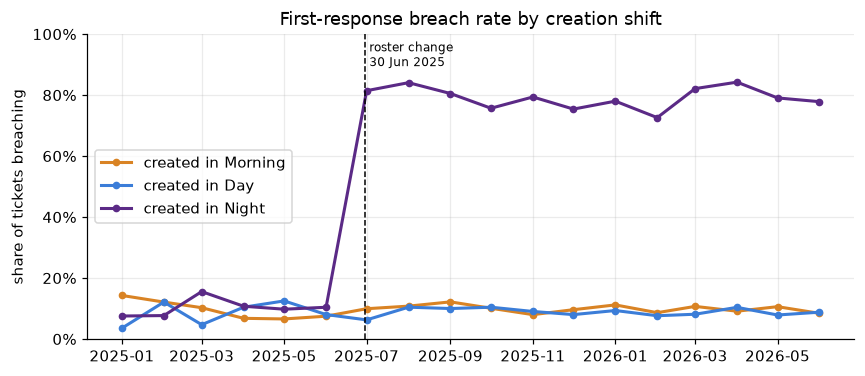

In [6]:
m = tk.groupby(['month', 'created_shift']).breach.agg(['sum', 'count']).unstack('created_shift')
rate = (m['sum'] / m['count'])[SHIFTS]; vol = m['count'][SHIFTS]
display(pd.concat({'breach rate': rate, 'tickets created': vol}, axis=1).round(3))

x = rate.index.to_timestamp()
fig, ax = plt.subplots(figsize=(9, 3.6))
for s in SHIFTS:
    ax.plot(x, rate[s], marker='o', ms=4, lw=2, label=f'created in {s}', color=COL[s])
ax.axvline(CUTOVER, color='k', ls='--', lw=1); ax.text(CUTOVER, .98, ' roster change\n 30 Jun 2025', va='top', fontsize=8)
ax.set(ylim=(0, 1), ylabel='share of tickets breaching', title='First-response breach rate by creation shift')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.legend(loc='center left')
plt.show()

## 4. Before vs after 30 Jun 2025

period,Before 30 Jun 2025,From 30 Jun 2025,change (pts),n before,n after,95% CI before,95% CI after
created_shift,,,,,,,
Morning,9.2%,9.9%,+0.7,841,3205,7.4%-11.3%,8.9%-11.0%
Day,8.6%,9.0%,+0.3,925,3743,7.0%-10.6%,8.1%-9.9%
Night,10.3%,79.1%,+68.8,487,1999,7.9%-13.3%,77.3%-80.8%


Morning  change +0.7 pts  (95% CI -1.5 to +2.9)
Day      change +0.3 pts  (95% CI -1.7 to +2.3)
Night    change +68.8 pts  (95% CI +65.6 to +72.1)


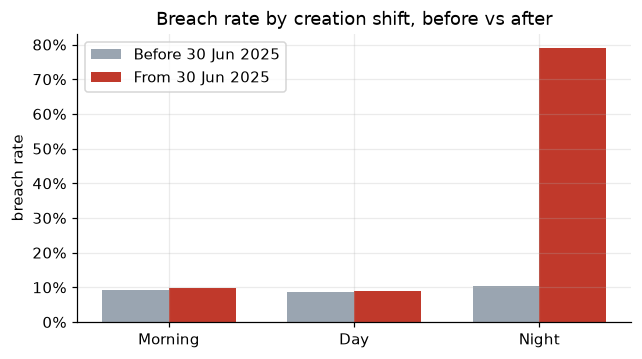

In [7]:
def summarise(d, by):
    g = d.groupby(by).breach.agg(k='sum', n='count')
    g['rate'] = g.k / g.n
    g['lo'], g['hi'] = wilson(g.k, g.n)
    return g

ba = summarise(tk, ['created_shift', 'period'])
tab = ba.rate.unstack('period')[PERIODS]
tab['change (pts)'] = (tab[PERIODS[1]] - tab[PERIODS[0]]) * 100
tab['n before'] = ba.n.unstack('period')[PERIODS[0]]; tab['n after'] = ba.n.unstack('period')[PERIODS[1]]
tab['95% CI before'] = [f'{ba.lo[s, PERIODS[0]]:.1%}-{ba.hi[s, PERIODS[0]]:.1%}' for s in tab.index]
tab['95% CI after'] = [f'{ba.lo[s, PERIODS[1]]:.1%}-{ba.hi[s, PERIODS[1]]:.1%}' for s in tab.index]
tab = tab.loc[SHIFTS]
display(tab.style.format({PERIODS[0]: '{:.1%}', PERIODS[1]: '{:.1%}', 'change (pts)': '{:+.1f}'}))

# Change in rate, with a normal-approx 95% CI on the difference in proportions
def diff_ci(shift):
    b, a = ba.loc[(shift, PERIODS[0])], ba.loc[(shift, PERIODS[1])]
    d = a.rate - b.rate; se = sqrt(a.rate*(1-a.rate)/a.n + b.rate*(1-b.rate)/b.n)
    return d, d - 1.96*se, d + 1.96*se
for s in SHIFTS:
    d, lo, hi = diff_ci(s); print(f'{s:8s} change {d*100:+.1f} pts  (95% CI {lo*100:+.1f} to {hi*100:+.1f})')

fig, ax = plt.subplots(figsize=(6.5, 3.4)); w = .36; xs = np.arange(3)
for i, p in enumerate(PERIODS):
    ax.bar(xs + (i - .5) * w, [tab.loc[s, p] for s in SHIFTS], w, label=p, color=['#9aa5b1', '#c0392b'][i])
ax.set_xticks(xs, SHIFTS); ax.set(ylabel='breach rate', title='Breach rate by creation shift, before vs after'); ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); plt.show()

## 5. Breach rate by hour of day (IST) - is the jump confined to Night hours?

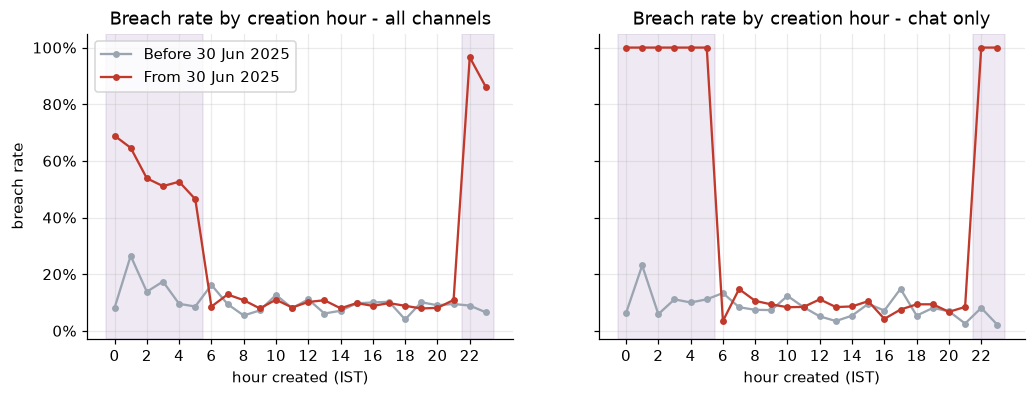

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
period,,,,,,,,,,,,,,,,,,,,,,,,
Before 30 Jun 2025,0.080,0.260,0.140,0.170,0.100,0.090,0.160,0.090,0.050,0.070,0.130,0.080,0.110,0.060,0.070,0.100,0.100,0.100,0.040,0.100,0.090,0.090,0.090,0.070
From 30 Jun 2025,0.690,0.650,0.540,0.510,0.530,0.460,0.090,0.130,0.110,0.080,0.110,0.080,0.100,0.110,0.080,0.100,0.090,0.100,0.090,0.080,0.080,0.110,0.970,0.860
n after,225.000,178.000,104.000,92.000,95.000,114.000,117.000,195.000,305.000,456.000,528.000,572.000,550.000,482.000,478.000,429.000,398.000,419.000,499.000,520.000,531.000,469.000,761.000,430.000


Daytime hours (06-21) breach rate, before -> after: 8.9% -> 9.4%
Night hours (22-05) breach rate, before -> after:    10.3% -> 79.1%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, d) in zip(axes, [('all channels', tk), ('chat only', tk[tk.channel == 'chat'])]):
    for p, c in zip(PERIODS, ['#9aa5b1', '#c0392b']):
        h = d[d.period == p].groupby('hour').breach.mean().reindex(range(24))
        ax.plot(h.index, h.values, marker='o', ms=3.5, label=p, color=c)
    ax.axvspan(-.5, 5.5, color=COL['Night'], alpha=.10); ax.axvspan(21.5, 23.5, color=COL['Night'], alpha=.10)
    ax.set(title=f'Breach rate by creation hour - {name}', xlabel='hour created (IST)', xticks=range(0, 24, 2))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[0].set_ylabel('breach rate'); axes[0].legend(); plt.show()

hh = tk.groupby(['hour', 'period']).breach.mean().unstack('period')[PERIODS]
hh['n after'] = tk[tk.period == PERIODS[1]].groupby('hour').size()
display(hh.T.round(2))
night_h = [22, 23, 0, 1, 2, 3, 4, 5]
print('Daytime hours (06-21) breach rate, before -> after:',
      ' -> '.join(f"{tk[(tk.period == p) & ~tk.hour.isin(night_h)].breach.mean():.1%}" for p in PERIODS))
print('Night hours (22-05) breach rate, before -> after:   ',
      ' -> '.join(f"{tk[(tk.period == p) & tk.hour.isin(night_h)].breach.mean():.1%}" for p in PERIODS))

### 5b. Mechanism check - when do night tickets actually get their first reply?

,tickets,median_wait_h,p75_wait_h,first_reply_in_06_14,breach_rate
period,,,,,
Before 30 Jun 2025,487,0.4,2.4,13%,10%
From 30 Jun 2025,1999,7.4,8.4,100%,79%


                    tickets  median_wait_h  p75_wait_h  first_reply_in_06_14  breach_rate
period                                                                                   
Before 30 Jun 2025      487          0.370       2.420                 0.130        0.100
From 30 Jun 2025       1999          7.420       8.370                 1.000        0.790


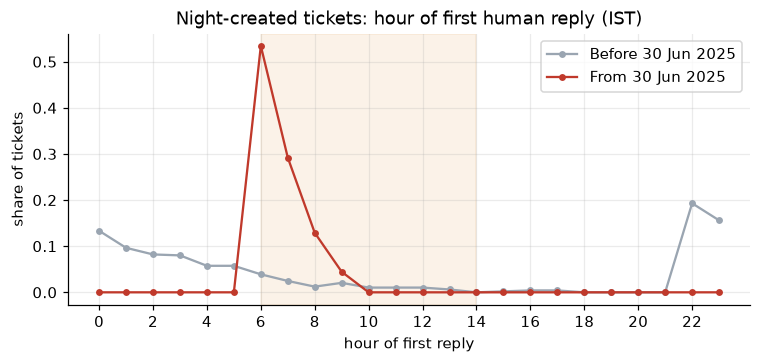

In [9]:
night = tk[tk.created_shift == 'Night'].copy()
night['resp_hour'] = night.first_response_at_ist.dt.hour
night['resp_in_morning_shift'] = night.resp_hour.between(6, 13)
night['wait_h'] = night.resp_min / 60
mech = night.groupby('period').agg(tickets=('ticket_id', 'count'),
                                   median_wait_h=('wait_h', 'median'),
                                   p75_wait_h=('wait_h', lambda s: s.quantile(.75)),
                                   first_reply_in_06_14=('resp_in_morning_shift', 'mean'),
                                   breach_rate=('breach', 'mean')).loc[PERIODS]
display(mech.style.format({'median_wait_h': '{:.1f}', 'p75_wait_h': '{:.1f}', 'first_reply_in_06_14': '{:.0%}', 'breach_rate': '{:.0%}'}))
print(mech.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.2))
for p, c in zip(PERIODS, ['#9aa5b1', '#c0392b']):
    s = night[night.period == p].resp_hour.value_counts(normalize=True).reindex(range(24), fill_value=0)
    ax.plot(s.index, s.values, marker='o', ms=3.5, color=c, label=p)
ax.axvspan(6, 14, color=COL['Morning'], alpha=.10)
ax.set(title='Night-created tickets: hour of first human reply (IST)', xlabel='hour of first reply', xticks=range(0, 24, 2), ylabel='share of tickets')
ax.legend(); plt.show()

### 5c. Did the night backlog spill onto Morning-created tickets?

Morning agents inherit the night queue (policy section 7). If that backlog crowded out new morning work, Morning-created tickets would start breaching too. They are compared with Day-created tickets, which sit behind no backlog.

In [10]:
sp = tk[tk.created_shift != 'Night'].groupby(['channel', 'created_shift', 'period']).breach.agg(rate='mean', n='size').unstack('period')
display(sp.style.format({(m_, p_): '{:.1%}' for m_ in ['rate'] for p_ in PERIODS}))

early = tk[tk.hour.between(6, 9) & (tk.created_shift == 'Morning')]
print('Morning-created tickets in the first hours of the shift (06:00-09:59), breach rate before -> after:',
      ' -> '.join(f"{early[early.period == p].breach.mean():.1%} (n={int((early.period == p).sum())})" for p in PERIODS))

# Morning-created vs Day-created, from 30 Jun 2025
a = ba.loc[('Morning', PERIODS[1])]; b = ba.loc[('Day', PERIODS[1])]
d = a.rate - b.rate; se = sqrt(a.rate*(1-a.rate)/a.n + b.rate*(1-b.rate)/b.n)
print(f'Morning-created minus Day-created breach rate from 30 Jun 2025: {d*100:+.1f} pts (95% CI {(d-1.96*se)*100:+.1f} to {(d+1.96*se)*100:+.1f})')

Morning-created tickets in the first hours of the shift (06:00-09:59), breach rate before -> after: 8.4% (n=275) -> 9.7% (n=1073)
Morning-created minus Day-created breach rate from 30 Jun 2025: +0.9 pts (95% CI -0.4 to +2.3)


## 6. Breaches by the resolving agent's shift vs the ticket's creation shift

In [11]:
res = tk[tk.status.isin(['resolved', 'closed'])].copy()
res['res_shift_date'] = (res.resolved_at_ist.fillna(res.created_at_ist) - pd.Timedelta(hours=6)).dt.normalize()

# the roster row in force on the day the ticket was resolved (agents can have several rows)
j = res.reset_index().merge(roster, on='agent_id', how='left')
j = j[(j.res_shift_date >= j.from_date) & (j.res_shift_date <= j.to_date)]
assert j['index'].is_unique and len(j) == len(res), (len(j), len(res))
res = res.join(j.set_index('index')[['name', 'site', 'team', 'agent_shift', 'tier']])
res['same_shift'] = res.created_shift == res.agent_shift
print(f'{len(res):,} resolved/closed tickets matched to exactly one roster row')

br = res[res.breach]
def cross(d):
    c = pd.crosstab(d.created_shift, d.agent_shift).reindex(index=SHIFTS, columns=SHIFTS, fill_value=0)
    c.index.name = 'created in / resolved by'; return c
for p in PERIODS:
    print(f'\n=== Breaches, {p}  (rows: shift ticket was created in, columns: shift of the agent who resolved it)')
    display(cross(br[br.period == p]).assign(total=lambda d: d.sum(axis=1)))

post = br[br.period == PERIODS[1]]
by_res = post.agent_shift.value_counts().reindex(SHIFTS, fill_value=0); by_cre = post.created_shift.value_counts().reindex(SHIFTS, fill_value=0)
print('\nFrom 30 Jun 2025, share of ALL breaches:')
print(pd.DataFrame({'attributed to resolver shift': by_res / by_res.sum(), 'created in shift': by_cre / by_cre.sum()}).map(lambda v: f'{v:.0%}').to_string())
mm = post[post.agent_shift == 'Morning']
print(f'\nBreaches resolved by Morning agents: {len(mm):,}; of which created in Night: {(mm.created_shift == "Night").sum():,} ({(mm.created_shift == "Night").mean():.0%}), '
      f'Morning: {(mm.created_shift == "Morning").mean():.0%}, Day: {(mm.created_shift == "Day").mean():.0%}')
nt = res[(res.created_shift == 'Night') & (res.period == PERIODS[1])]
print('Night-created tickets from 30 Jun 2025 and who resolved them:', nt.agent_shift.value_counts(normalize=True).map('{:.0%}'.format).to_dict())

10,611 resolved/closed tickets matched to exactly one roster row



=== Breaches, Before 30 Jun 2025  (rows: shift ticket was created in, columns: shift of the agent who resolved it)


agent_shift,Morning,Day,Night,total
created in / resolved by,,,,
Morning,34,29,6,69
Day,31,33,14,78
Night,34,5,7,46



=== Breaches, From 30 Jun 2025  (rows: shift ticket was created in, columns: shift of the agent who resolved it)


agent_shift,Morning,Day,Night,total
created in / resolved by,,,,
Morning,199,105,0,304
Day,164,156,0,320
Night,1455,48,0,1503



From 30 Jun 2025, share of ALL breaches:
        attributed to resolver shift created in shift
Morning                          85%              14%
Day                              15%              15%
Night                             0%              71%

Breaches resolved by Morning agents: 1,818; of which created in Night: 1,455 (80%), Morning: 11%, Day: 9%
Night-created tickets from 30 Jun 2025 and who resolved them: {'Morning': '97%', 'Day': '3%'}


## 7. Each Tier-1 agent judged only on tickets created in their own shift

In [12]:
t1 = res[res.tier == 1].copy()                       # Tier 2 is measured on resolution days, not on this (policy section 6)

def agent_table(d):
    a = d.groupby('agent_id').agg(name=('name', 'first'), team=('team', 'first'), site=('site', 'first'),
                                   shifts=('agent_shift', lambda s: '/'.join(sorted(set(s), key=SHIFTS.index))),
                                   resolved=('breach', 'size'), breaches_attributed=('breach', 'sum'))
    own = d[d.same_shift].groupby('agent_id').breach.agg(own_tickets='size', own_breaches='sum')
    a = a.join(own).fillna({'own_tickets': 0, 'own_breaches': 0})
    a['attributed_rate'] = a.breaches_attributed / a.resolved
    a['own_shift_rate'] = a.own_breaches / a.own_tickets.replace(0, np.nan)
    a['own_lo'], a['own_hi'] = wilson(a.own_breaches, a.own_tickets)
    return a

ag_all = agent_table(t1)
base = t1[t1.same_shift].breach.mean()
ag_all['vs_own_shift_baseline'] = np.where(ag_all.own_lo > base, 'above', np.where(ag_all.own_hi < base, 'below', 'in line'))
print(f"Tier-1 agents: {len(ag_all)}.  Baseline = breach rate on tickets created in the resolver's own shift, all Tier-1: {base:.1%}")
show = ['name', 'team', 'site', 'shifts', 'resolved', 'attributed_rate', 'own_tickets', 'own_shift_rate', 'vs_own_shift_baseline']
fmt = {'attributed_rate': '{:.1%}', 'own_shift_rate': '{:.1%}'}
display(ag_all.sort_values('attributed_rate', ascending=False)[show].style.format(fmt))
print('\nAgents vs the own-shift baseline (95% Wilson interval excludes the baseline):')
print(ag_all.vs_own_shift_baseline.value_counts().to_string())

Tier-1 agents: 38.  Baseline = breach rate on tickets created in the resolver's own shift, all Tier-1: 6.4%


,name,team,site,shifts,resolved,attributed_rate,own_tickets,own_shift_rate,vs_own_shift_baseline
agent_id,,,,,,,,,
A3009,Ramesh Patel,Chat Frontline,Bengaluru,Morning,190,42.6%,103,4.9%,in line
A3011,Karan Roy,Chat Frontline,Indore,Morning,198,41.9%,115,7.8%,in line
A3010,Neha Chatterjee,Chat Frontline,Indore,Morning,208,41.8%,125,10.4%,in line
A3014,Diya Patil,Chat Frontline,Bengaluru,Morning,189,41.8%,110,6.4%,in line
A3013,Ritika Chatterjee,Chat Frontline,Indore,Morning,226,41.6%,136,10.3%,in line
A3008,Steven Kaur,Chat Frontline,Indore,Morning,184,38.0%,118,7.6%,in line
A3032,Aadhya Sheikh,Billing,Indore,Morning,348,37.4%,162,9.3%,in line
A3005,Sameer Joshi,Chat Frontline,Bengaluru,Morning,208,36.5%,129,7.0%,in line
A3007,Neha Gaikwad,Chat Frontline,Bengaluru,Morning,201,34.3%,135,5.9%,in line



Agents vs the own-shift baseline (95% Wilson interval excludes the baseline):
vs_own_shift_baseline
in line    33
below       4
above       1


,tickets resolved,attributed breach rate (helpdesk report view),breaches attributed,own-shift tickets,own-shift breach rate,breaches on own-shift tickets
period,,,,,,
Before 30 Jun 2025,901,9.2%,83,581,5.3%,31
From 30 Jun 2025,4591,36.8%,1688,2260,8.3%,187


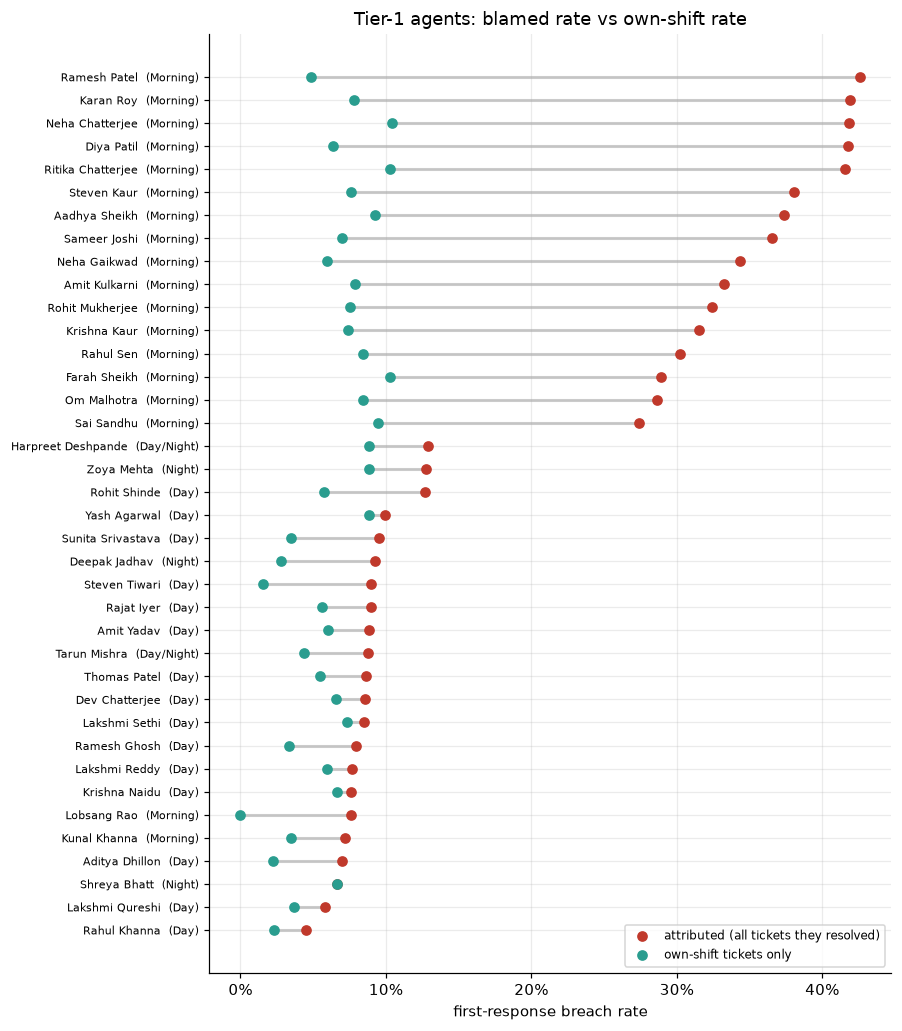

In [13]:
# Morning-shift Tier-1 agents, before vs after the roster change
mo = t1[t1.agent_shift == 'Morning']
rows = []
for p in PERIODS:
    d = mo[mo.period == p]; o = d[d.same_shift]
    rows.append({'period': p, 'tickets resolved': len(d), 'attributed breach rate (helpdesk report view)': d.breach.mean(),
                 'breaches attributed': int(d.breach.sum()), 'own-shift tickets': len(o), 'own-shift breach rate': o.breach.mean(),
                 'breaches on own-shift tickets': int(o.breach.sum())})
display(pd.DataFrame(rows).set_index('period').style.format({'attributed breach rate (helpdesk report view)': '{:.1%}', 'own-shift breach rate': '{:.1%}'}))

# Dumbbell: attributed vs own-shift, agents with a usable own-shift sample
dd = ag_all[ag_all.own_tickets >= 30].sort_values('attributed_rate')
fig, ax = plt.subplots(figsize=(8, 0.26 * len(dd) + 1.2))
ypos = np.arange(len(dd))
ax.hlines(ypos, dd.own_shift_rate, dd.attributed_rate, color='#ccc', lw=2, zorder=1)
ax.scatter(dd.attributed_rate, ypos, color='#c0392b', label='attributed (all tickets they resolved)', zorder=2)
ax.scatter(dd.own_shift_rate, ypos, color='#2a9d8f', label='own-shift tickets only', zorder=3)
ax.set_yticks(ypos, [f'{n}  ({s})' for n, s in zip(dd.name, dd.shifts)], fontsize=7.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.set(xlabel='first-response breach rate', title='Tier-1 agents: blamed rate vs own-shift rate')
ax.legend(loc='lower right', fontsize=8); plt.show()

### 7b. What the Night gap costs in SLA credits (policy section 3: Rs 350 per breached ticket, issued on resolution)

In [14]:
CREDIT = 350
nr = res[(res.created_shift == 'Night')]
base_rate = nr[nr.period == PERIODS[0]].breach.mean()
post_n = nr[nr.period == PERIODS[1]]
excess = post_n.breach.sum() - base_rate * len(post_n)
months = post_n.created_at_ist.dt.to_period('M').nunique()
print(f'Night-created resolved/closed tickets from 30 Jun 2025: {len(post_n):,}; breached {int(post_n.breach.sum()):,} ({post_n.breach.mean():.1%}) vs {base_rate:.1%} before')
print(f'Excess breaches over the pre-change Night rate: {excess:,.0f}  ->  Rs {excess * CREDIT:,.0f} of credits over {months} months (about Rs {excess * CREDIT / months:,.0f} per month)')
mcred = (res.assign(m=res.created_at_ist.dt.to_period('M')).groupby('m').breach.sum() * CREDIT)
print('Credits by month created (Rs):'); print(mcred.to_string())

Night-created resolved/closed tickets from 30 Jun 2025: 1,898; breached 1,503 (79.2%) vs 9.9% before
Excess breaches over the pre-change Night rate: 1,315  ->  Rs 460,193 of credits over 13 months (about Rs 35,399 per month)
Credits by month created (Rs):
m
2025-01     7000
2025-02    14000
2025-03    11550
2025-04    12950
2025-05    12950
2025-06    10500
2025-07    36400
2025-08    61950
2025-09    60550
2025-10    70350
2025-11    71750
2025-12    65100
2026-01    70700
2026-02    52150
2026-03    67200
2026-04    64050
2026-05    61950
2026-06    60900
Freq: M


## 8. Scorecard

In [15]:
sc = {}
sc['1. Night roster rows from 30 Jun 2025'] = f"{int(hc.loc['2025-06-30':, 'Night'].max())} agents (was {int(hc.loc['2025-06-29', 'Night'])} on 29 Jun)"
sc['2a. Night-created breach rate, before -> after'] = f"{tab.loc['Night', PERIODS[0]]:.1%} -> {tab.loc['Night', PERIODS[1]]:.1%}"
sc['2b. Morning-created breach rate, before -> after'] = f"{tab.loc['Morning', PERIODS[0]]:.1%} -> {tab.loc['Morning', PERIODS[1]]:.1%}"
sc['2c. Day-created breach rate, before -> after'] = f"{tab.loc['Day', PERIODS[0]]:.1%} -> {tab.loc['Day', PERIODS[1]]:.1%}"
sc['3. Daytime hours (06-21) breach rate, before -> after'] = ' -> '.join(f"{tk[(tk.period == p) & ~tk.hour.isin(night_h)].breach.mean():.1%}" for p in PERIODS)
sc['3. Night hours (22-05) breach rate, before -> after'] = ' -> '.join(f"{tk[(tk.period == p) & tk.hour.isin(night_h)].breach.mean():.1%}" for p in PERIODS)
sc['4. Night-created share of breaches resolved by Morning agents (from 30 Jun)'] = f"{(mm.created_shift == 'Night').mean():.0%}"
mo_post = mo[mo.period == PERIODS[1]]; mo_own = mo_post[mo_post.same_shift]
sc['5. Morning agents: attributed vs own-shift breach rate (from 30 Jun)'] = f"{mo_post.breach.mean():.1%} vs {mo_own.breach.mean():.1%}"
sc['   Day-shift Tier-1 own-shift rate, same period'] = f"{t1[(t1.period == PERIODS[1]) & (t1.agent_shift == 'Day') & t1.same_shift].breach.mean():.1%}"
sc['Mechanism: Night tickets first answered 06:00-14:00 (before -> after)'] = ' -> '.join(f"{mech.loc[p, 'first_reply_in_06_14']:.0%}" for p in PERIODS)
sc['Morning agents flagged above baseline on own-shift tickets'] = f"{int(((ag_all.vs_own_shift_baseline == 'above') & ag_all.shifts.str.contains('Morning')).sum())} of {int(ag_all.shifts.str.contains('Morning').sum())}"
display(pd.Series(sc, name='result').to_frame())

,result
1. Night roster rows from 30 Jun 2025,0 agents (was 5 on 29 Jun)
"2a. Night-created breach rate, before -> after",10.3% -> 79.1%
"2b. Morning-created breach rate, before -> after",9.2% -> 9.9%
"2c. Day-created breach rate, before -> after",8.6% -> 9.0%
"3. Daytime hours (06-21) breach rate, before -> after",8.9% -> 9.4%
"3. Night hours (22-05) breach rate, before -> after",10.3% -> 79.1%
4. Night-created share of breaches resolved by Morning agents (from 30 Jun),80%
5. Morning agents: attributed vs own-shift breach rate (from 30 Jun),36.8% vs 8.3%
"Day-shift Tier-1 own-shift rate, same period",5.6%
Mechanism: Night tickets first answered 06:00-14:00 (before -> after),13% -> 100%


## 9. Verdict: the hypothesis is supported

| Test | Result |
|---|---|
| 1. Night roster after 29 Jun 2025 | 5 agents on 29 Jun, **0 from 30 Jun** (2 moved to Day, 3 have no later roster row) |
| 2. Night-created breach rate | **10.3% to 79.1%** (+68.8 pts, 95% CI +65.6 to +72.1). Morning-created 9.2% to 9.9% (+0.7, CI -1.5 to +2.9); Day-created 8.6% to 9.0% (+0.3, CI -1.7 to +2.3) |
| 3. Hour of day | Hours 22:00-05:59 jump from 10.3% to 79.1%; hours 06:00-21:59 stay at 8.9% to 9.4% |
| 4. Who carries the breaches | From 30 Jun, Morning agents resolve 85% of all breaches, but only 14% of breaches were created in the Morning shift. **80%** of the breaches on Morning agents' tickets (1,455 of 1,818) were created at night, and 97% of Night-created tickets end up with a Morning resolver |
| 5. Morning agents on their own tickets | Attributed breach rate **36.8%**, but only **8.3%** on tickets created in their own shift (Day agents: 5.6%). 1 of 18 Morning agents is flagged above baseline, about what chance alone gives across 38 Tier-1 agents |

**Mechanism.** Night-created tickets had a median first-reply wait of 0.4 h before the change and 7.4 h after. Every one of them (100%, up from 13%) now gets its first human reply between 06:00 and 14:00 IST, which is the Morning shift. They then breach (chat 15 min, social 4 h, email 8 h) and the helpdesk report (policy section 3) books the breach against whoever resolves the ticket.

**Ruling out the obvious alternatives.**
- *Demand surge:* Night ticket volume was flat across the change (96 created in Jun 2025, 97 in Jul).
- *Backlog spill onto the Morning shift's own tickets:* Morning-created tickets breach at 9.9% versus 9.0% for Day-created (difference +0.9 pts, CI -0.4 to +2.3), and the first hours of the shift (06:00-09:59) are 8.4% before and 9.7% after.
- *Bad clock:* every voice-callback request falls inside 08:00-22:00 only with a +05:30 shift. Left in UTC, 37% of voice tickets would sit outside IVR hours.

**Caveats.**
- `agent_id` is the resolver, so the data cannot name who typed the first reply. The case rests on the empty Night roster and on every Night ticket's first reply landing in the 06:00-14:00 window.
- This is a before/after on one date, not a controlled experiment. The timing is sharp (July 2025 is already 81%) and nothing else moves, but it is still timing evidence.
- Morning agents' own-shift rate is 2.7 pts above Day agents'. The creation-shift gap is only +0.9 pts and not distinguishable from zero. Most of the remaining difference looks like a resolver-selection effect (late-answered tickets get resolved by whoever picks them up), so I would not read it as a Morning-team problem, but it is worth watching.
- Open and pending tickets are excluded from the resolver views, since `agent_id` is not a resolver there.

**Consequence for the report.** Reporting breaches by resolving agent and shift will keep showing the Morning team as "the bulk of the breaches" while the cause sits in the Night gap. The report should attribute breaches to the shift the ticket was *created* in, show resolver attribution next to it, and treat the Night gap as a coverage question, not a Morning-team performance question. The gap also explains the SLA credit line: at Rs 350 per breach, credits on tickets created each month rose from about Rs 11,000 (Jan-Jun 2025) to roughly Rs 50,000-70,000 a month from Aug 2025 (section 7b). The credit line is not flat, contrary to what the thread says.